# Exploration - prediction de retard de paiement

Ce notebook lit les donnees synthetiques dans PostgreSQL. Il n'entraine pas encore de modele.

In [1]:
from pathlib import Path
import os
import pandas as pd
import psycopg

def load_env_file(path: Path) -> None:
    for line in path.read_text(encoding="utf-8").splitlines():
        if line and not line.startswith("#") and "=" in line:
            key, value = line.split("=", 1)
            os.environ.setdefault(key.strip(), value.strip())

env_candidates = [Path(".env"), Path("..") / ".env"]
env_file = next((path for path in env_candidates if path.exists()), None)

if env_file is None:
    raise FileNotFoundError("Fichier .env introuvable.")

load_env_file(env_file)

database_url = os.getenv("ML_DATABASE_URL")
if not database_url or "<MOT_DE_PASSE>" in database_url:
    raise RuntimeError("Configure ML_DATABASE_URL dans le fichier .env avant de continuer.")

In [3]:
query = 'SELECT * FROM ml_training.retard_features ORDER BY facture_key'
with psycopg.connect(database_url) as connection:
    data = pd.read_sql(query, connection)

data.head()

C:\Users\nourb\AppData\Local\Temp\ipykernel_3340\1496269518.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  data = pd.read_sql(query, connection)


,facture_key,client_key,date_emission,montant_ttc,jours_delai,mode_paiement,type_client,ville,anciennete_mois,nombre_factures_precedentes,nombre_retards_precedents,taux_retard_precedent,retard_moyen_jours,retard
0,1,38,2024-01-14,279.1,30,Cheque,B2B,Sousse,79,0,0,0.0,0.0,0
1,2,75,2024-01-27,358.2,30,Especes,B2C,Ariana,26,1,0,0.0,-2.0,0
2,3,112,2024-02-09,437.3,45,Carte,B2B,Nabeul,88,1,0,0.0,-3.0,0
3,4,149,2024-02-22,516.4,30,Virement,B2B,Monastir,35,1,0,0.0,-4.0,0
4,5,186,2024-03-06,595.5,60,Cheque,B2B,Tunis,97,2,1,0.5,3.5,0


In [4]:
resume = data['retard'].value_counts().rename(index={0: 'paiement_a_temps', 1: 'retard'})
resume

retard
paiement_a_temps    6463
retard              3037
Name: count, dtype: int64

In [5]:
features = [
    "montant_ttc",
    "jours_delai",
    "mode_paiement",
    "type_client",
    "ville",
    "anciennete_mois",
    "nombre_factures_precedentes",
    "nombre_retards_precedents",
    "taux_retard_precedent",
    "retard_moyen_jours",
]

X = data[features].copy()
y = data["retard"].copy()

print("Taille de X :", X.shape)
print("\nRépartition de y :")
print(y.value_counts())

Taille de X : (9500, 10)

Répartition de y :
retard
0    6463
1    3037
Name: count, dtype: int64


In [6]:
data_ml = data.sort_values("date_emission").reset_index(drop=True)

split_index = int(len(data_ml) * 0.80)

train_data = data_ml.iloc[:split_index]
test_data = data_ml.iloc[split_index:]

X_train = train_data[features]
y_train = train_data["retard"]

X_test = test_data[features]
y_test = test_data["retard"]

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)
print("Dernière date entraînement :", train_data["date_emission"].max())
print("Première date test :", test_data["date_emission"].min())   

Entraînement : (7600, 10)
Test : (1900, 10)
Dernière date entraînement : 2025-10-17
Première date test : 2025-10-17


In [7]:
data_ml = data.sort_values("date_emission").reset_index(drop=True)

dates_uniques = data_ml["date_emission"].drop_duplicates().sort_values().to_list()
date_coupure = dates_uniques[int(len(dates_uniques) * 0.80)]

train_data = data_ml[data_ml["date_emission"] < date_coupure]
test_data = data_ml[data_ml["date_emission"] >= date_coupure]

X_train = train_data[features]
y_train = train_data["retard"]

X_test = test_data[features]
y_test = test_data["retard"]

print("Date de coupure :", date_coupure)
print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)
print("Dernière date entraînement :", train_data["date_emission"].max())
print("Première date test :", test_data["date_emission"].min())

Date de coupure : 2025-10-18
Entraînement : (7604, 10)
Test : (1896, 10)
Dernière date entraînement : 2025-10-17
Première date test : 2025-10-18


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_features = [
    "montant_ttc",
    "jours_delai",
    "anciennete_mois",
    "nombre_factures_precedentes",
    "nombre_retards_precedents",
    "taux_retard_precedent",
    "retard_moyen_jours",
]

categorical_features = [
    "mode_paiement",
    "type_client",
    "ville",
]

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numerical_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Modèle entraîné avec succès.")

Modèle entraîné avec succès.


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Modèle entraîné avec succès.")

Modèle entraîné avec succès.


Matplotlib is building the font cache; this may take a moment.


ROC-AUC : 0.998

                  precision    recall  f1-score   support

paiement à temps       0.97      0.99      0.98      1290
          retard       0.97      0.94      0.96       606

        accuracy                           0.97      1896
       macro avg       0.97      0.96      0.97      1896
    weighted avg       0.97      0.97      0.97      1896



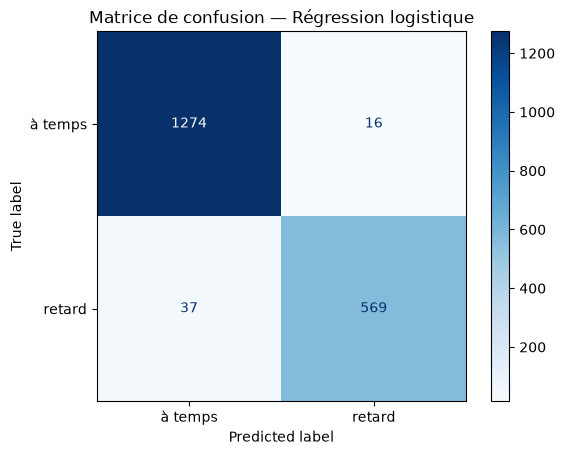

In [11]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

print("ROC-AUC :", round(roc_auc_score(y_test, y_prob), 3))
print()
print(classification_report(
    y_test,
    y_pred,
    target_names=["paiement à temps", "retard"],
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["à temps", "retard"],
    cmap="Blues",
)

plt.title("Matrice de confusion — Régression logistique")
plt.show()

In [12]:
from sklearn.ensemble import HistGradientBoostingClassifier

boosting_preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numerical_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ]
)

boosting_model = Pipeline(
    steps=[
        ("preprocessor", boosting_preprocessor),
        (
            "classifier",
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.05,
                max_leaf_nodes=15,
                l2_regularization=0.1,
                random_state=42,
            ),
        ),
    ]
)

boosting_model.fit(X_train, y_train)

boosting_pred = boosting_model.predict(X_test)
boosting_prob = boosting_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting entraîné avec succès.")

Gradient Boosting entraîné avec succès.


ROC-AUC Gradient Boosting : 1.0

                  precision    recall  f1-score   support

paiement à temps       1.00      1.00      1.00      1290
          retard       1.00      1.00      1.00       606

        accuracy                           1.00      1896
       macro avg       1.00      1.00      1.00      1896
    weighted avg       1.00      1.00      1.00      1896



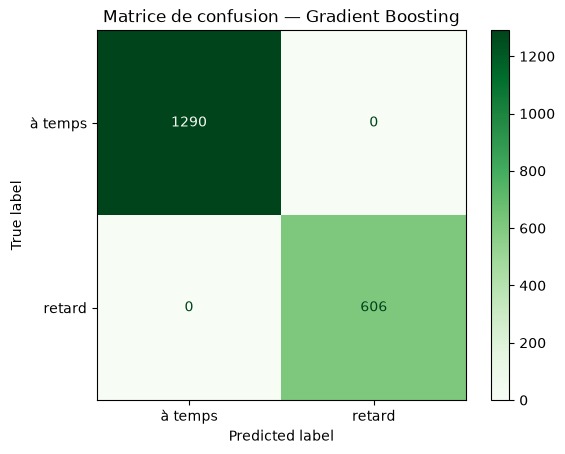

In [13]:

print("ROC-AUC Gradient Boosting :", round(roc_auc_score(y_test, boosting_prob), 3))
print()

print(classification_report(
    y_test,
    boosting_pred,
    target_names=["paiement à temps", "retard"],
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    boosting_pred,
    display_labels=["à temps", "retard"],
    cmap="Greens",
)

plt.title("Matrice de confusion — Gradient Boosting")
plt.show()

In [14]:
from pathlib import Path
import joblib

project_root = Path.cwd()
if not (project_root / "models").exists():
    project_root = Path("..")

model_path = project_root / "models" / "retard_model.joblib"

joblib.dump(boosting_model, model_path)

print("Modèle sauvegardé dans :", model_path.resolve())

Modèle sauvegardé dans : C:\backendpfe\einvoicing\ml_service\models\retard_model.joblib


In [15]:
sample = X_test.iloc[[0]]

risk_probability = boosting_model.predict_proba(sample)[0, 1]
prediction = boosting_model.predict(sample)[0]
actual_result = y_test.iloc[0]

print("Probabilité de retard :", round(risk_probability * 100, 2), "%")
print("Prédiction :", "retard" if prediction == 1 else "paiement à temps")
print("Résultat réel :", "retard" if actual_result == 1 else "paiement à temps")

sample

Probabilité de retard : 0.01 %
Prédiction : paiement à temps
Résultat réel : paiement à temps


,montant_ttc,jours_delai,mode_paiement,type_client,ville,anciennete_mois,nombre_factures_precedentes,nombre_retards_precedents,taux_retard_precedent,retard_moyen_jours
7604,7979.2,30,Virement,B2C,Ariana,41,14,0,0.0,-3.571


In [ ]:
sample = X_test.iloc[[0]]

risk_probability = boosting_model.predict_proba(sample)[0, 1]
prediction = boosting_model.predict(sample)[0]
actual_result = y_test.iloc[0]

print("Probabilité de retard :", round(risk_probability * 100, 2), "%")
print("Prédiction :", "retard" if prediction == 1 else "paiement à temps")
print("Résultat réel :", "retard" if actual_result == 1 else "paiement à temps")

sample